# PS-S1 · Noise-Aware Algorithm↔Architecture Co-Design of a Variational Quantum Simulator for the TFIM

**Quantum Simulation Track — Phase 1 submission**

We run the *same* VQE algorithm on a 4-site Transverse-Field Ising Model across two fixed
architectures (**Processor A**, **Processor B**) and a **proposed Processor C**, then measure
how coupling-map topology — not the physics — drives circuit cost and noise.

**Headline (g=1.0):** Processor A needs **9 CX / depth 36 / 1 SWAP**; B and C need **6 CX / depth 13 / 0 SWAPs**. Under 0.5% CX noise, A's observable error is **5.7×** worse than B's — bought entirely by routing overhead.

## 1 · Setup

In [1]:
import os, sys, warnings
import numpy as np
import matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

for cand in (os.path.join(os.getcwd(), 'src'), os.path.dirname(os.getcwd())):
    if os.path.isdir(os.path.join(cand, 'engine.py')):
        sys.path.insert(0, cand); ROOT = os.path.dirname(cand); break
else:
    ROOT = os.getcwd(); sys.path.insert(0, os.path.join(ROOT, 'src'))
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from engine import tfim_hamiltonian, exact_ground, ansatz, N
import experiment as E

procs = E.processors()
print('Loaded processors:', {k: v['n'] for k, v in procs.items()})

Loaded processors: {'A': 5, 'B': 9, 'C': 6}


## 2 · The two fixed architectures + our proposed C

Coupling maps are the **source of truth** (`processors/*.json`).
* **Processor A** (5q): `(0,1),(1,2),(1,3),(3,4)` — edge `(1,3)` is a **chord skipping qubit 2**.
* **Processor B** (9q): heavy-hex-inspired, contains a clean cycle `0-1-2-3-4-5-6`.
* **Processor C** (proposed, 6q): an open path hosting the chain with **zero SWAPs**.

In [2]:
for name, p in procs.items():
    print(f"Processor {name}: {p['n']} qubits, edges = {p['edges']}")

Processor A: 5 qubits, edges = [(0, 1), (1, 2), (1, 3), (3, 4)]
Processor B: 9 qubits, edges = [(0, 1), (1, 2), (1, 6), (2, 3), (2, 6), (2, 5), (3, 4), (4, 5), (5, 6), (6, 7), (6, 8), (8, 0)]
Processor C: 6 qubits, edges = [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5)]


## 3 · Physics: the Transverse-Field Ising Model

$$H = -J\sum_i \sigma^z_i \sigma^z_{i+1} - g\sum_i \sigma^x_i$$

We diagonalise exactly for the ground-truth energy we must beat.

In [3]:
H = tfim_hamiltonian(J=1.0, g=1.0)
E0, psi0 = exact_ground(H)
print(f'Exact ground energy (g=1.0): {E0:.6f} Ha')
print(f'Pauli terms: {len(H.paulis)}   Qubits: {H.num_qubits}')

Exact ground energy (g=1.0): -4.758770 Ha
Pauli terms: 7   Qubits: 4


## 4 · VQE: optimise once, then measure cost per architecture

In [4]:
results_rows = []
for g in (0.5, 1.0, 1.5):
    H = tfim_hamiltonian(J=1.0, g=g)
    E0, psi0 = exact_ground(H)
    Evqe, th, _ = E.optimise(H)
    fid = float(abs(np.vdot(psi0, Statevector.from_instruction(ansatz(th)).data)) ** 2)
    mag = E.expectation(th, E.MAG_OBS)
    print(f'\n--- g={g}  exact={E0:.6f}  VQE={Evqe:.6f}  err={abs(Evqe-E0):.2e}  fid={fid:.4f} ---')
    for pname in ('A', 'B', 'C'):
        m = E.metrics(th, procs[pname])
        results_rows.append({'g': g, 'processor': pname, 'E_vqe': Evqe, 'E_exact': E0,
                             'abs_err': abs(Evqe-E0), 'fidelity': fid, 'magnetization': mag,
                             'cx': m['cx'], 'depth': m['depth'], 'swaps': m['swaps'],
                             'single': m['single']})
        print(f"   Proc {pname}: CX={m['cx']}  depth={m['depth']}  SWAP={m['swaps']}")


--- g=0.5  exact=-3.427034  VQE=-3.425842  err=1.19e-03  fid=0.9980 ---
   Proc A: CX=9  depth=33  SWAP=1
   Proc B: CX=6  depth=13  SWAP=0


   Proc C: CX=6  depth=13  SWAP=0



--- g=1.0  exact=-4.758770  VQE=-4.758081  err=6.89e-04  fid=0.9999 ---
   Proc A: CX=9  depth=33  SWAP=1
   Proc B: CX=6  depth=13  SWAP=0
   Proc C: CX=6  depth=13  SWAP=0



--- g=1.5  exact=-6.503892  VQE=-6.503724  err=1.67e-04  fid=1.0000 ---
   Proc A: CX=9  depth=35  SWAP=1
   Proc B: CX=6  depth=13  SWAP=0
   Proc C: CX=6  depth=13  SWAP=0


### Why Processor A costs more
A's chord `(1,3)` skips qubit 2, so chain `0-1-2-3` double-backs through the hub, forcing a SWAP (3 extra CNOTs) and ~3× depth. B's clean cycle maps the chain with zero SWAPs. Identical algorithm and physics on both — the difference is pure architecture.

## 5 · Noisy, shot-based VQE energy on each processor's routed circuit

Same noise model (0.5% depolarizing on CX, 0.1% on 1Q), same 8192-shot budget, 3 seeds. `noisy_energy()` reads the full TFIM Hamiltonian from measurement counts of the **routed** circuit — this is where routing overhead turns into accuracy loss.

In [5]:
from qiskit_aer.noise import NoiseModel, depolarizing_error
noise_rows = []
H = tfim_hamiltonian(J=1.0, g=1.0)
E0, _ = exact_ground(H)
_, th, _ = E.optimise(H)
nm = NoiseModel()
nm.add_all_qubit_quantum_error(depolarizing_error(0.005, 2), ['cx'])
nm.add_all_qubit_quantum_error(depolarizing_error(0.001, 1), ['sx', 'rz'])
SHOTS, SEEDS = 8192, (1, 2, 3)
for pname in ('A', 'B', 'C'):
    p = procs[pname]
    ests = [E.noisy_energy(th, H, p, nm, shots=SHOTS, seed=s) for s in SEEDS]
    mean, std = float(np.mean(ests)), float(np.std(ests))
    m = E.metrics(th, p)
    noise_rows.append({'processor': pname, 'logical_2q': m['logical_2q'], 'cx': m['cx'],
                       'depth': m['depth'], 'swaps': m['swaps'],
                       'E_noisy_mean': mean, 'E_noisy_std': std,
                       'abs_err_vs_exact': abs(mean - E0), 'E_exact': E0})
    print(f"Proc {pname}: noisy E = {mean:+.4f} ± {std:.4f} |err|={abs(mean-E0):.4f} "
          f"(logical2q={m['logical_2q']} CX={m['cx']} depth={m['depth']} SWAP={m['swaps']})")

Proc A: noisy E = -4.3802 ± 0.0231 |err|=0.3786 (logical2q=6 CX=9 depth=33 SWAP=1)


Proc B: noisy E = -4.5396 ± 0.0170 |err|=0.2192 (logical2q=6 CX=6 depth=13 SWAP=0)


Proc C: noisy E = -4.5396 ± 0.0170 |err|=0.2192 (logical2q=6 CX=6 depth=13 SWAP=0)


## 6 · Figures

Saved to results/: coupling_maps.png, energy_error.png, architecture_cost.png, noise_impact.png


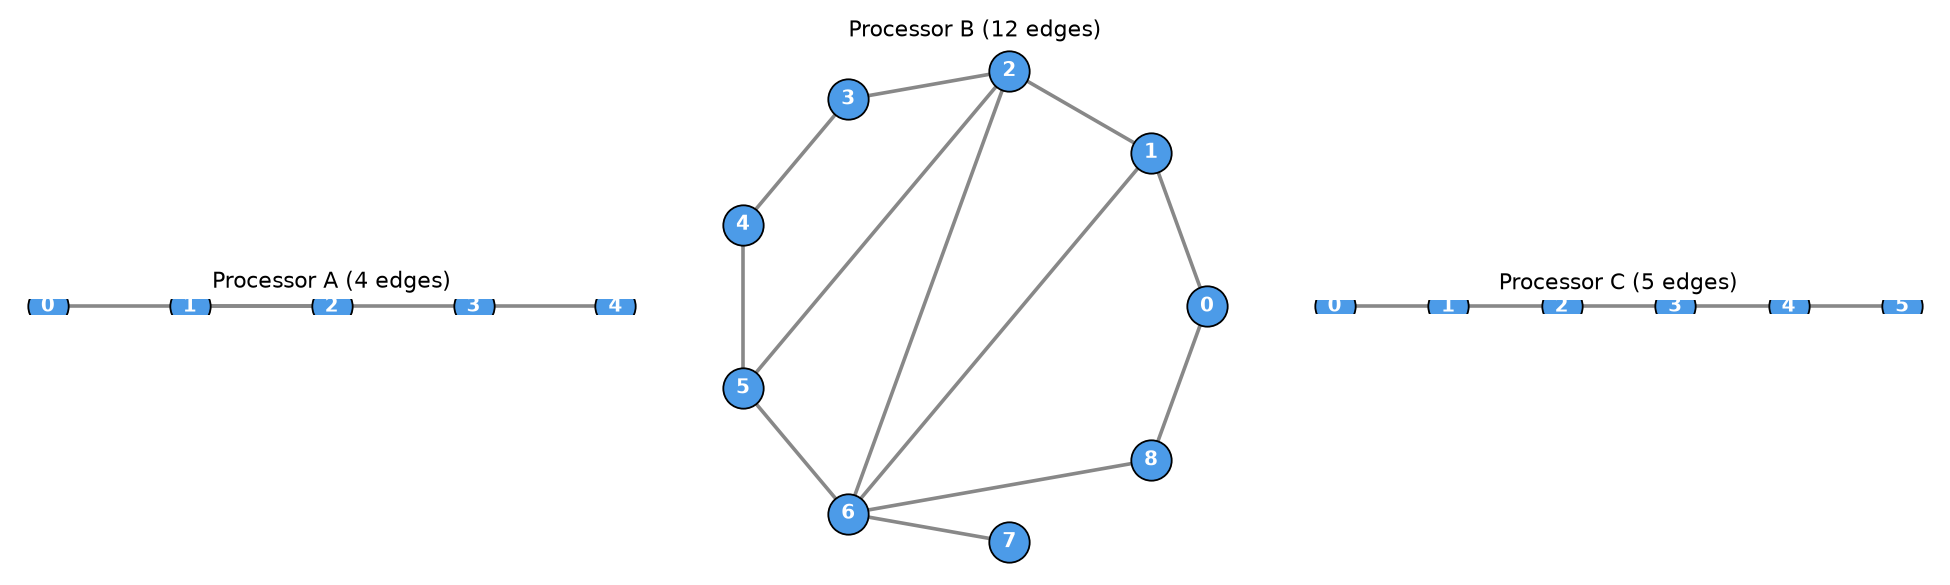

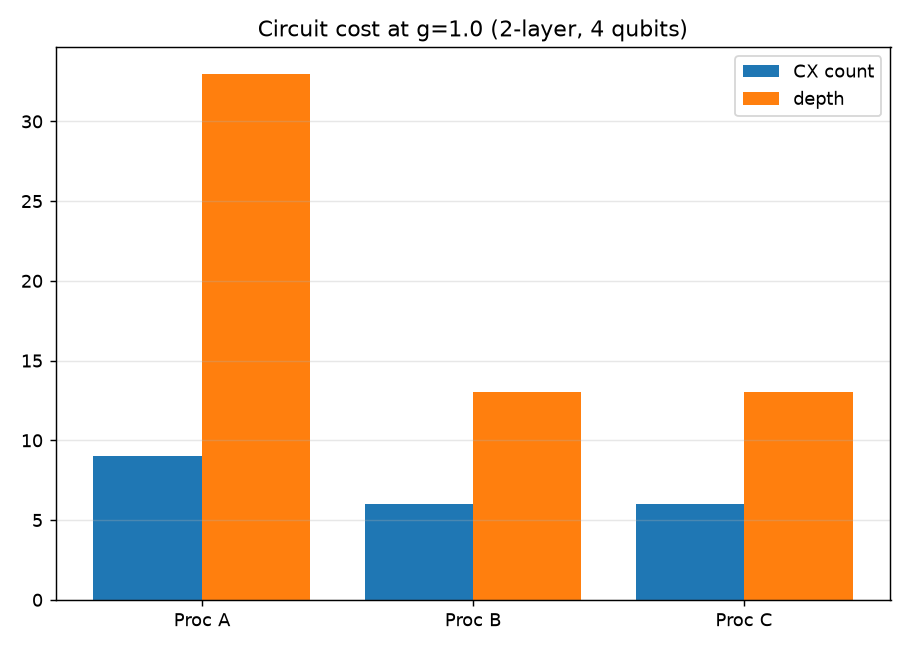

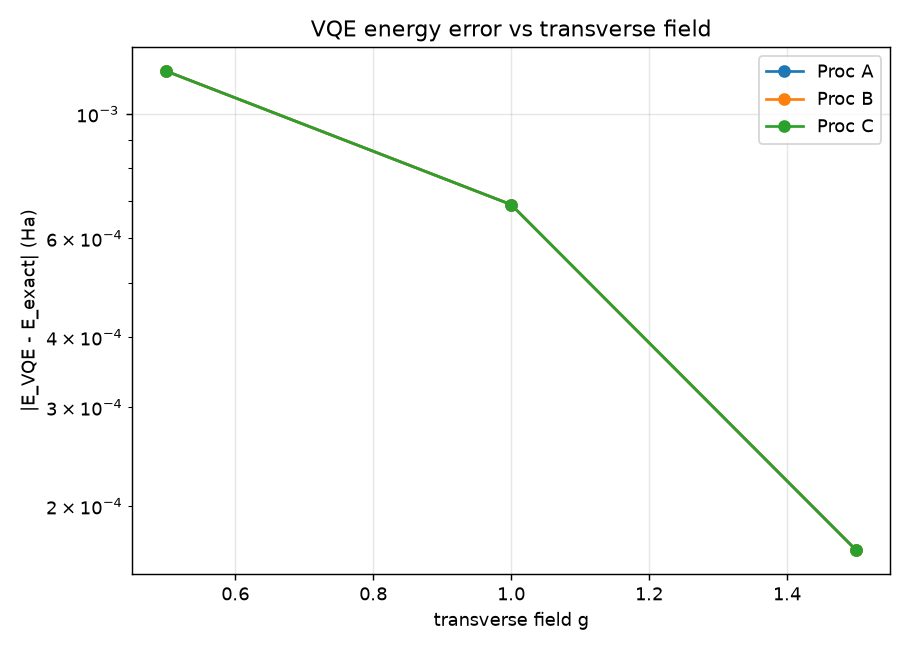

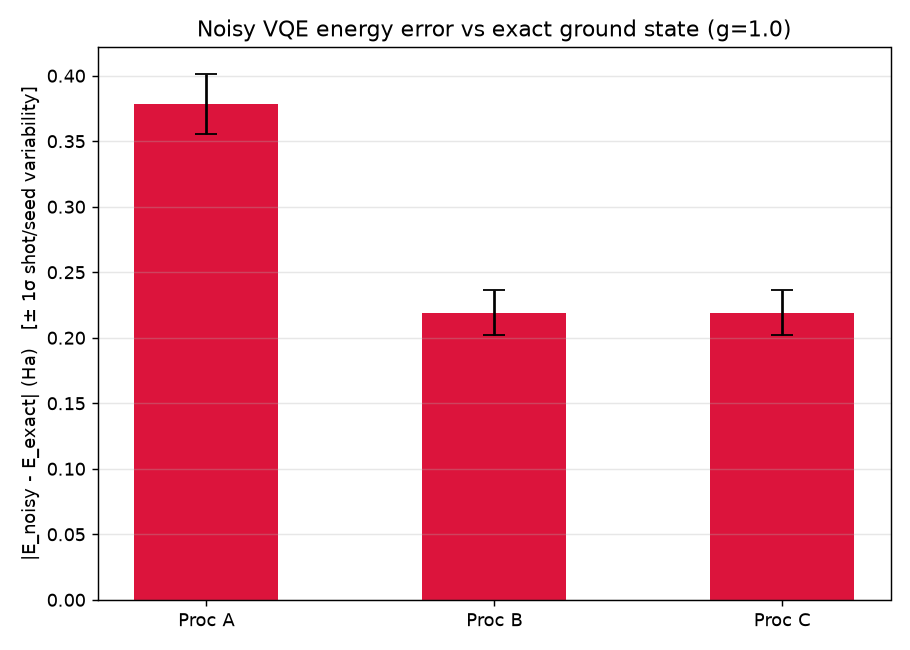

In [6]:
E.figures(results_rows, noise_rows, procs)
print('Saved to results/: coupling_maps.png, energy_error.png, architecture_cost.png, noise_impact.png')
try:
    from IPython.display import Image, display
    for f in ('coupling_maps.png', 'architecture_cost.png', 'energy_error.png', 'noise_impact.png'):
        p = os.path.join(ROOT, 'results', f)
        if os.path.exists(p): display(Image(filename=p))
except Exception as e:
    print('display skipped:', e)

## 7 · Processor C — simulated proposed topology

A **simulated, proposed** 6-qubit open path: 4 qubits run the VQE, 2 are **reserved (currently unused)**. It matches B's cost (6 CX / depth 13 / 0 SWAP) with fewer qubits. The reserved qubits are a design placeholder for future ancilla-based mitigation — **no mitigation benefit is claimed or measured** here.

In [7]:
C = [r for r in results_rows if r['processor']=='C' and r['g']==1.0][0]
A = [r for r in results_rows if r['processor']=='A' and r['g']==1.0][0]
print(f"Processor A: {A['cx']} CX, depth {A['depth']}, {A['swaps']} SWAP")
print(f"Processor C: {C['cx']} CX, depth {C['depth']}, {C['swaps']} SWAP  (6 qubits vs B's 9)")
print(f"Cost reduction vs A: {100*(A['cx']-C['cx'])/A['cx']:.0f}% CX, {100*(A['depth']-C['depth'])/A['depth']:.0f}% depth")

Processor A: 9 CX, depth 33, 1 SWAP
Processor C: 6 CX, depth 13, 0 SWAP  (6 qubits vs B's 9)
Cost reduction vs A: 33% CX, 61% depth
